# Jour 4 — Visualisations

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1705/chapter/4336), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## Exercice 1 — Utilité
Les graphiques rendent visibles distributions, tendances, écarts et anomalies que des moyennes seules peuvent masquer. Ils servent à explorer et à communiquer, avec des axes et unités explicites. Une courbe relie des points ordonnés, notamment dans le temps, pour suivre une évolution ; elle convient moins à des catégories sans ordre.

## Exercice 2 — Températures

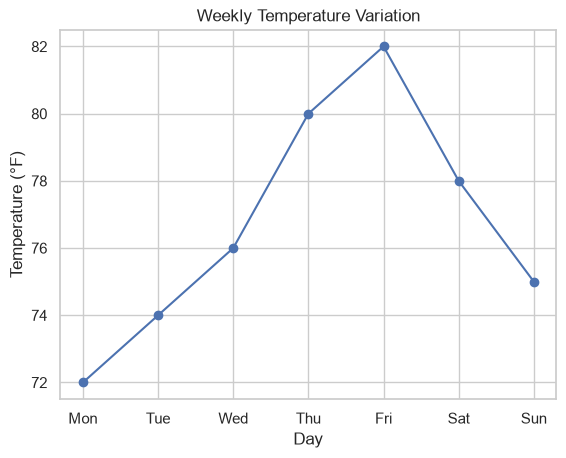

In [2]:
plt.plot(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"],[72,74,76,80,82,78,75],marker="o")
plt.xlabel("Day");plt.ylabel("Temperature (°F)");plt.title("Weekly Temperature Variation");plt.show()

## Exercice 3 — Ventes mensuelles

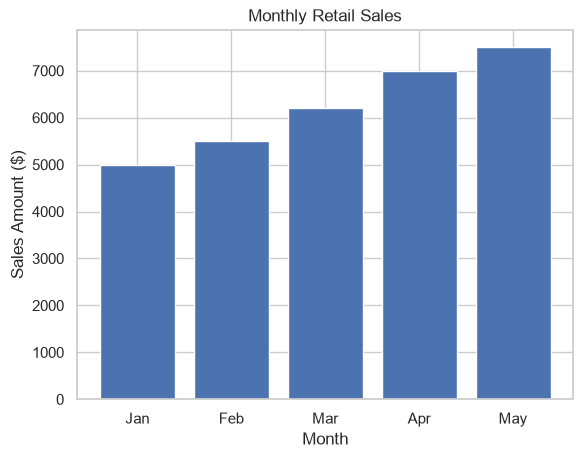

In [3]:
plt.bar(["Jan","Feb","Mar","Apr","May"],[5000,5500,6200,7000,7500])
plt.xlabel("Month");plt.ylabel("Sales Amount ($)");plt.title("Monthly Retail Sales");plt.show()

## Exercice 4 — Distribution du CGPA
Le CGPA est fourni sous forme d’intervalles, pas de notes exactes. On compte donc les catégories ordonnées avec histplot discret sans inventer de notes.

,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


,manquants
Timestamp,0
Choose your gender,0
Age,1
What is your course?,0
Your current year of Study,0
What is your CGPA?,0
Marital status,0
Do you have Depression?,0
Do you have Anxiety?,0
Do you have Panic attack?,0


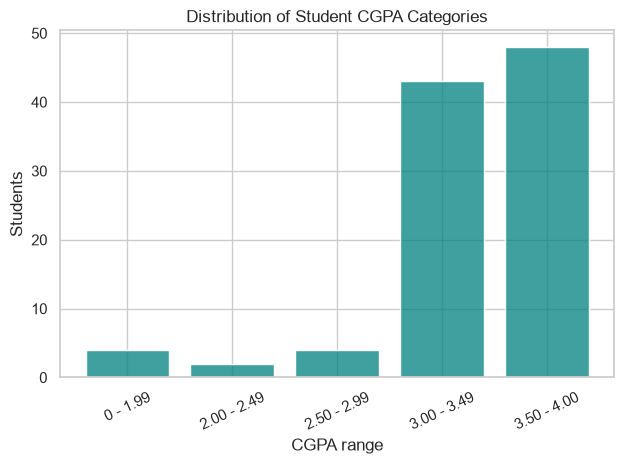

In [4]:
df=pd.read_csv(course_file("Datasets-GEN-AI-Bootcamp","Week 3/W3D1 - Data Visualization/Student Mental health.zip","Student Mental health.csv"))
display(df.head());display(df.isna().sum().to_frame("manquants"))
col="What is your CGPA?";df[col]=df[col].str.strip()
order=sorted(df[col].dropna().unique(),key=lambda x:float(x.split("-")[0].strip()))
df[col]=pd.Categorical(df[col],categories=order,ordered=True)
sns.histplot(data=df.sort_values(col),x=col,discrete=True,color="teal",shrink=.8)
plt.xlabel("CGPA range");plt.ylabel("Students");plt.title("Distribution of Student CGPA Categories");plt.xticks(rotation=25);plt.tight_layout();plt.show()

## Exercice 5 — Proportion d’anxiété par genre
Moyenne de l’indicateur Yes=1 : proportion dans chaque groupe, et non simple nombre de réponses positives. Les effectifs sont affichés pour contextualiser la comparaison.

,count,mean
Choose your gender,,
Female,75,0.320000
Male,26,0.384615


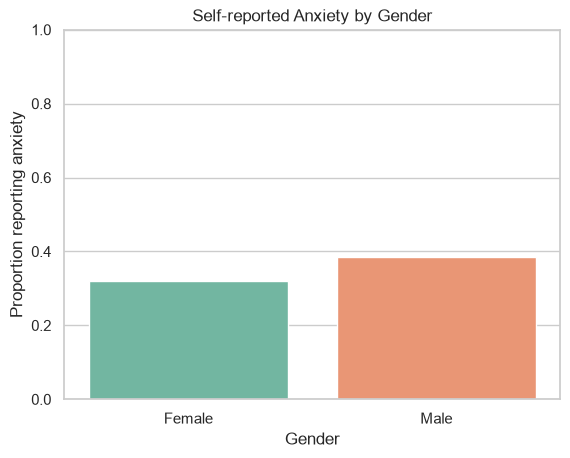

In [5]:
df["Anxiety"]=df["Do you have Anxiety?"].str.strip().map({"Yes":1,"No":0})
assert df["Anxiety"].notna().all()
display(df.groupby("Choose your gender")["Anxiety"].agg(["count","mean"]))
sns.barplot(data=df,x="Choose your gender",y="Anxiety",hue="Choose your gender",palette="Set2",legend=False,errorbar=None)
plt.ylim(0,1);plt.xlabel("Gender");plt.ylabel("Proportion reporting anxiety");plt.title("Self-reported Anxiety by Gender");plt.show()

## Exercice 6 — Âge et attaques de panique
Le fichier réel nomme la colonne Panic attack au singulier. Les âges manquants sont exclus de ce seul graphique ; on ne leur attribue pas un âge inventé. L’axe binaire et la transparence facilitent la lecture des points superposés.

Observations tracées 100 exclues 1


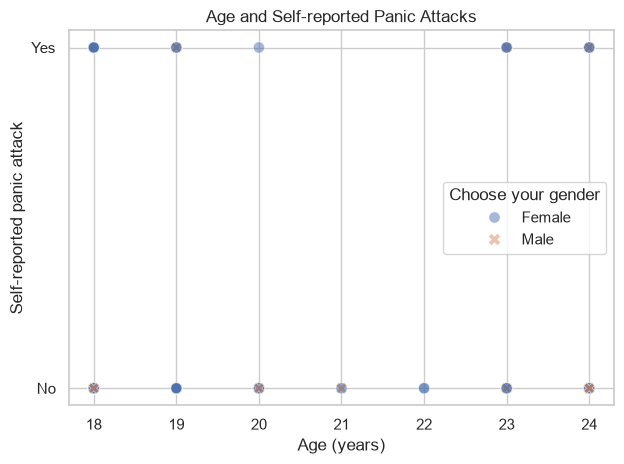

,count,mean
Age,,
18.0,32,0.281250
19.0,21,0.428571
20.0,6,0.166667
21.0,3,0.000000
22.0,2,0.000000
23.0,13,0.384615
24.0,23,0.391304


In [6]:
df["Panic"]=df["Do you have Panic attack?"].str.strip().map({"Yes":1,"No":0})
plot_df=df.dropna(subset=["Age","Panic"])
print("Observations tracées",len(plot_df),"exclues",len(df)-len(plot_df))
sns.scatterplot(data=plot_df,x="Age",y="Panic",hue="Choose your gender",style="Choose your gender",alpha=.5,s=65)
plt.yticks([0,1],["No","Yes"]);plt.xlabel("Age (years)");plt.ylabel("Self-reported panic attack");plt.title("Age and Self-reported Panic Attacks");plt.tight_layout();plt.show()
display(plot_df.groupby("Age")["Panic"].agg(["count","mean"]))

Ces données déclaratives de 101 étudiants constituent un échantillon limité. Les graphiques décrivent les répondants ; ils ne justifient ni diagnostic individuel ni généralisation à tous les étudiants.